<a href="https://colab.research.google.com/github/NoeliaFerrero/Comi-96160-Data-Science-II-Machine-Learning-para-la-Ciencia-de-Datos-Diplomaturas/blob/main/Semana%2017%20Datathon%20en%20DS/Guia_Proyecto_DS_Punta_a_Punta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Si mañana les presentan un problema real de una empresa y no saben qué algoritmo utilizar, ¿eso significa que no están preparados para empezar un proyecto de Data Science?**

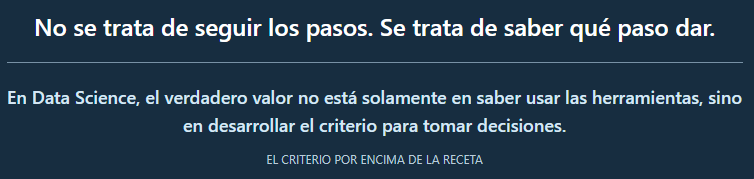


# Proyecto de Data Science de punta a punta
## De una pregunta a una decision (sin recetas magicas)

**Objetivo de este notebook:** recorrer las decisiones principales de un proyecto de Data Science y reconocer qué entregable produce cada etapa.

> **Idea central:** esto es una guía de navegación, no una receta universal. El orden y las técnicas cambian según el problema, los datos, el contexto y el impacto esperado.

### Mapa del recorrido
1. Entender el problema y definir el éxito.
2. Conocer los datos y su origen.
3. Explorar (EDA): detectar patrones, problemas y preguntas nuevas.
4. Preparar datos y diseñar una estrategia de evaluación.
5. Construir una referencia (*baseline*) y, si corresponde, modelos.
6. Evaluar, interpretar errores y decidir si el resultado sirve.
7. Comunicar hallazgos, recomendaciones y limitaciones.
8. Pensar cómo se usaría, monitorearía y mantendría la solución.

**Importante:** no todos los proyectos necesitan Machine Learning. Un análisis descriptivo, una segmentación, un tablero o una regla simple pueden ser la mejor solución.

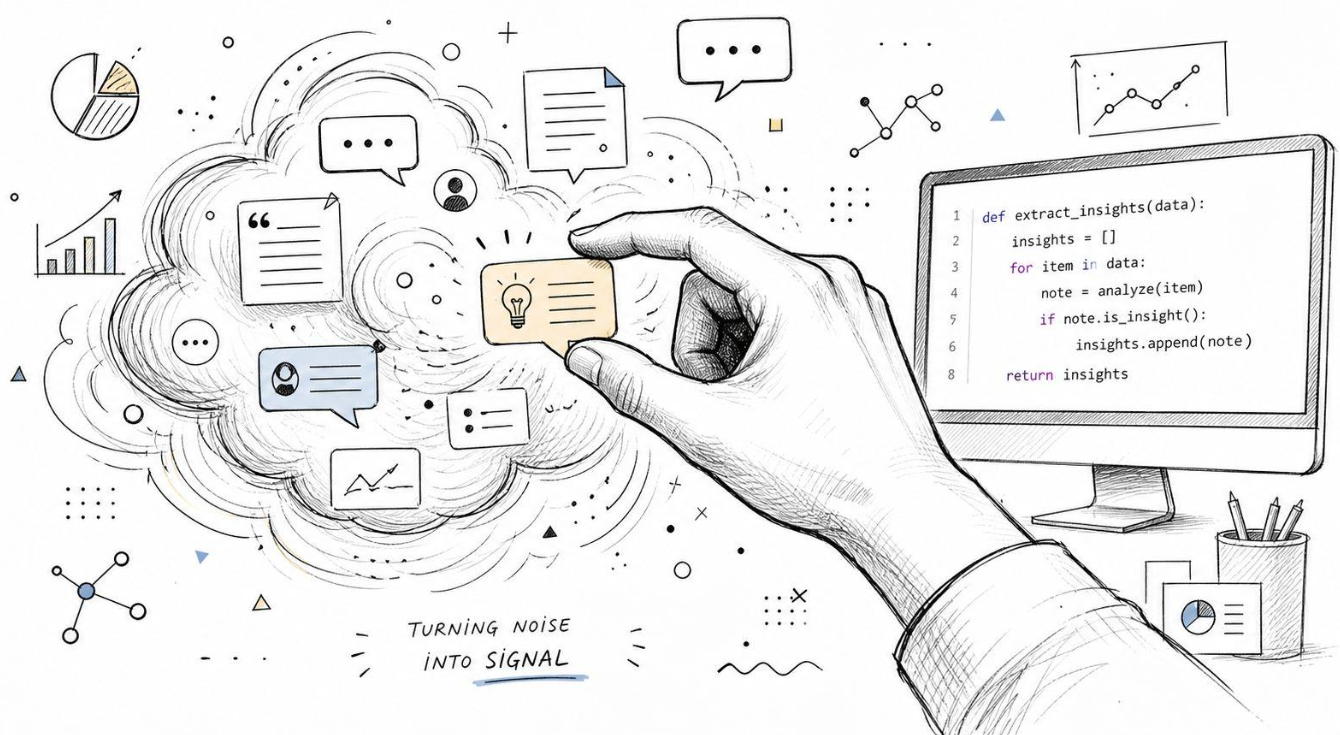

## 0. Antes de tocar los datos: encuadrar el problema

Un pedido como *“quiero predecir quién abandona”* todavía no es un problema suficientemente definido.

Antes de programar, conviene acordar:

- **Contexto:** ¿qué está pasando y por qué importa?
- **Usuario de la solución:** ¿quién tomará decisiones con el resultado?
- **Decisión concreta:** ¿qué podría hacer esa persona si obtiene información útil?
- **Pregunta analítica:** ¿qué necesitamos conocer o estimar?
- **Unidad de análisis:** ¿qué representa una fila? (persona, curso, compra, día…)
- **Horizonte temporal:** ¿cuándo se quiere anticipar el fenómeno?
- **Éxito:** ¿cómo sabremos que el análisis fue útil?
- **Restricciones:** datos disponibles, privacidad, tiempo, recursos y sesgos posibles.

### Caso didáctico
Una plataforma educativa quiere comprender y anticipar qué estudiantes podrían no completar un curso, para ofrecer acompañamiento oportuno.

**No confundamos:** detectar una asociación no demuestra causalidad; predecir un riesgo no explica automáticamente por qué ocurre ni garantiza que una intervención funcione.

## 1. Datos del caso (sintéticos)

Para que el notebook se pueda ejecutar sin descargar archivos ni depender de enlaces externos, construiremos un dataset ficticio. **No representa estudiantes reales ni permite conclusiones sobre una institución.** Sirve para practicar el flujo de trabajo.

Cada fila representa a un estudiante. El target `abandona` indica si no completó el curso.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n = 1200
edad = rng.integers(18, 60, n)
horas_semana = np.clip(rng.normal(5, 2.5, n), 0, 15).round(1)
entregas = rng.integers(0, 9, n)
participacion = rng.choice(["alta", "media", "baja"], n, p=[0.30, 0.45, 0.25])
modalidad = rng.choice(["sincrónica", "asincrónica"], n, p=[0.55, 0.45])

# Probabilidad artificial: solo para generar un ejemplo didáctico
logit = (
    -1.2
    - 0.22 * horas_semana
    - 0.20 * entregas
    + 0.85 * (participacion == "baja")
    + 0.25 * (participacion == "media")
    + 0.35 * (modalidad == "asincrónica")
)
prob_abandono = 1 / (1 + np.exp(-logit))
abandona = rng.binomial(1, prob_abandono)

df = pd.DataFrame({
    "edad": edad,
    "horas_semana": horas_semana,
    "entregas_realizadas": entregas,
    "participacion": participacion,
    "modalidad": modalidad,
    "abandona": abandona
})

# Introducimos algunos faltantes para practicar diagnóstico y tratamiento
for col, fraction in [("horas_semana", 0.04), ("participacion", 0.025)]:
    idx = rng.choice(df.index, size=int(fraction * n), replace=False)
    df.loc[idx, col] = np.nan

df.head()

,edad,horas_semana,entregas_realizadas,participacion,modalidad,abandona
0,21,8.1,8,baja,sincrónica,0
1,50,4.4,4,alta,asincrónica,0
2,45,5.9,5,baja,asincrónica,0
3,36,0.0,5,media,asincrónica,0
4,36,2.1,8,alta,asincrónica,0


## 2. Conocer los datos antes de analizarlos

Primero hacemos una inspección general. No alcanza con mirar cinco filas: necesitamos entender dimensiones, tipos, valores faltantes, duplicados y significado de las variables.

**Preguntas guía**
- ¿Qué representa una fila?
- ¿Qué representa cada columna?
- ¿Hay variables que no deberían estar disponibles al momento de tomar la decisión?
- ¿El target está definido de manera consistente?
- ¿Hay datos sensibles o restricciones de uso?

El diccionario de datos (aunque sea breve) es un entregable valioso.

In [ ]:
# Dimensiones y primeras filas
print("Filas y columnas:", df.shape)
display(df.head())

# Tipos, valores no nulos y memoria
df.info()

# Estadísticas iniciales
display(df.describe(include="all").T)

# Calidad básica
print("Duplicados:", df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False))

Filas y columnas: (1200, 6)


,edad,horas_semana,entregas_realizadas,participacion,modalidad,abandona
0,21,8.1,8,baja,sincrónica,0
1,50,4.4,4,alta,asincrónica,0
2,45,5.9,5,baja,asincrónica,0
3,36,0.0,5,media,asincrónica,0
4,36,2.1,8,alta,asincrónica,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   edad                 1200 non-null   int64  
 1   horas_semana         1152 non-null   float64
 2   entregas_realizadas  1200 non-null   int64  
 3   participacion        1170 non-null   object 
 4   modalidad            1200 non-null   object 
 5   abandona             1200 non-null   int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 56.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,1200.0,NaN,NaN,NaN,38.67,12.064302,18.0,28.0,39.0,49.0,59.0
horas_semana,1152.0,NaN,NaN,NaN,4.904167,2.485552,0.0,3.2,5.0,6.5,12.9
entregas_realizadas,1200.0,NaN,NaN,NaN,3.869167,2.586689,0.0,2.0,4.0,6.0,8.0
participacion,1170,3,media,528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modalidad,1200,2,sincrónica,699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
abandona,1200.0,NaN,NaN,NaN,0.068333,0.252422,0.0,0.0,0.0,0.0,1.0


Duplicados: 6


,0
horas_semana,48
participacion,30
edad,0
entregas_realizadas,0
modalidad,0
abandona,0


### Mini diccionario de datos

| Variable | Descripción | Tipo | Rol |
|---|---|---|---|
| edad | Edad del estudiante | Numérica | Predictor potencial |
| horas_semana | Horas dedicadas por semana | Numérica | Predictor potencial |
| entregas_realizadas | Cantidad de entregas | Numérica discreta | Predictor potencial |
| participacion | Nivel de participación | Categórica | Predictor potencial |
| modalidad | Modalidad cursada | Categórica | Predictor potencial |
| abandona | No completa el curso (1/0) | Binaria | Target |

Este diccionario es ilustrativo. En un proyecto real, las definiciones deben validarse con quienes conocen el dominio.

## 3. EDA: explorar para responder preguntas (no para coleccionar gráficos)

El EDA no es una galería de visualizaciones. Es una etapa para:
- entender distribuciones y composición;
- detectar problemas de calidad;
- encontrar patrones, diferencias y relaciones;
- formular hipótesis;
- decidir qué análisis o transformaciones tienen sentido después.

### 3.1 ¿Cómo se distribuye el target?

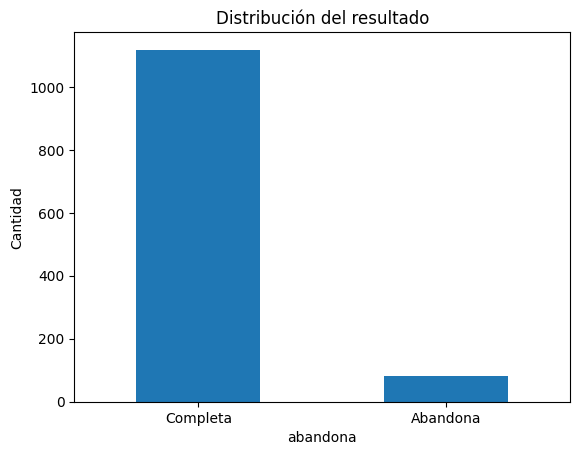

Proporción de abandono: 0.068


In [ ]:
df["abandona"].value_counts().rename(index={0: "Completa", 1: "Abandona"}).plot(
    kind="bar", rot=0, title="Distribución del resultado"
)
plt.ylabel("Cantidad")
plt.show()

print("Proporción de abandono:", round(df["abandona"].mean(), 3))

**Lectura:** la proporción de clases importa. Si el target está desbalanceado, accuracy puede resultar engañosa. La métrica se elige según la decisión y el costo de los errores, no por costumbre.

### 3.2 ¿Cómo se comportan las variables numéricas?

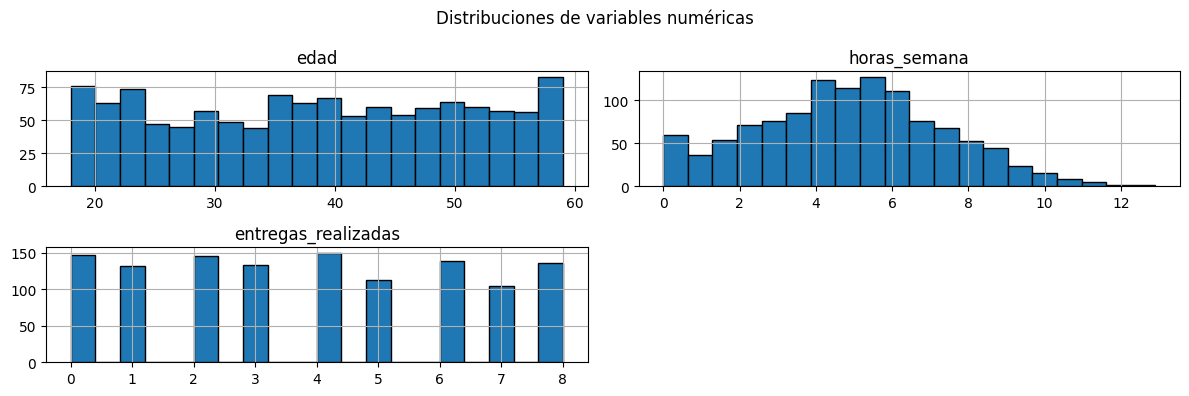

In [ ]:
df[["edad", "horas_semana", "entregas_realizadas"]].hist(
    figsize=(12, 4), bins=20, edgecolor="black"
)
plt.suptitle("Distribuciones de variables numéricas")
plt.tight_layout()
plt.show()

### 3.3 ¿Hay diferencias entre grupos?

Comparar una variable con el target puede ayudar a detectar señales. Estas diferencias son **descriptivas**, no prueban causalidad.

In [ ]:
df.groupby("participacion", dropna=False)["abandona"].agg(
    cantidad="size", tasa_abandono="mean"
).sort_values("tasa_abandono", ascending=False)

,cantidad,tasa_abandono
participacion,,
baja,292,0.106164
media,528,0.068182
alta,350,0.040000
NaN,30,0.033333


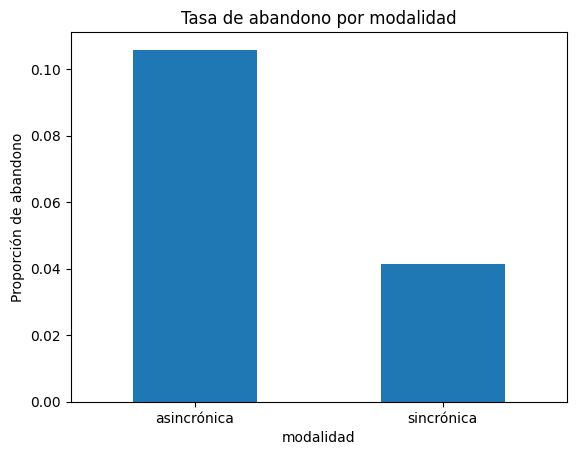

In [ ]:
df.groupby("modalidad")["abandona"].mean().plot(
    kind="bar", rot=0, title="Tasa de abandono por modalidad"
)
plt.ylabel("Proporción de abandono")
plt.show()

### 3.4 ¿Qué preguntas nuevas aparecen?

A partir de lo observado, podrían surgir preguntas como:
- ¿La participación baja aparece antes del abandono o es contemporánea?
- ¿Cuántas semanas de información tenemos disponibles?
- ¿La tasa cambia por cohorte o momento del curso?
- ¿Hay grupos con pocos casos que vuelvan inestable la comparación?
- ¿Qué variables podrían estar filtrando información futura (*data leakage*)?

**Salida del EDA:** hallazgos documentados, problemas de calidad, hipótesis, preguntas pendientes y decisiones para la siguiente etapa. No necesariamente un modelo.

## 4. Definir evaluación y separar los datos

Antes de entrenar, definimos cómo vamos a evaluar y reservamos datos que no usaremos para tomar decisiones durante el desarrollo.

En este ejemplo hacemos una partición estratificada:
- **train:** desarrollo, exploración de modelos y validación;
- **test:** evaluación final, una vez que las decisiones están cerradas.

> En datos temporales, grupos (personas, instituciones) o escenarios particulares, una división aleatoria puede ser incorrecta. La estrategia debe imitar el uso real y evitar fuga de información.

In [ ]:
X = df.drop(columns="abandona")
y = df["abandona"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción target train:", round(y_train.mean(), 3))
print("Proporción target test:", round(y_test.mean(), 3))

Train: (960, 5) | Test: (240, 5)
Proporción target train: 0.069
Proporción target test: 0.067


## 5. Preparar los datos: transformaciones reproducibles

Las transformaciones se aprenden con train y luego se aplican a validación/test. Así evitamos que información del test influya en el entrenamiento.

En este ejemplo:
- faltantes numéricos → mediana;
- faltantes categóricos → categoría más frecuente;
- categóricas → One-Hot Encoding;
- numéricas → estandarización.

No toda técnica necesita escalado; depende del algoritmo. Usar `Pipeline` ayuda a mantener las transformaciones junto con el modelo y reduce errores de procedimiento.

In [ ]:
numeric_features = ["edad", "horas_semana", "entregas_realizadas"]
categorical_features = ["participacion", "modalidad"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## 6. Baseline: ¿contra qué comparamos?

Antes de celebrar un modelo, necesitamos una referencia sencilla. Un baseline responde: **¿mejoramos algo respecto de una estrategia mínima o de la situación actual?**

Aquí usamos `DummyClassifier`, que predice siempre la clase más frecuente. No es una solución de negocio; es una referencia técnica.

In [ ]:
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

print("Accuracy baseline:", round(accuracy_score(y_test, pred_baseline), 3))
print(classification_report(y_test, pred_baseline, zero_division=0))

Accuracy baseline: 0.933
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       224
           1       0.00      0.00      0.00        16

    accuracy                           0.93       240
   macro avg       0.47      0.50      0.48       240
weighted avg       0.87      0.93      0.90       240



## 7. Entrenar un modelo sencillo y comparar

Usamos regresión logística como ejemplo interpretable y de clasificación. No estamos afirmando que sea el mejor algoritmo ni que el caso requiera ML: lo usamos para ilustrar el flujo.

**Antes de elegir métricas, preguntamos:** ¿qué error es más costoso?
- **Falso negativo:** no identificamos a alguien que abandona.
- **Falso positivo:** señalamos a alguien que finalmente completa.

Si el objetivo fuera ofrecer apoyo, quizá convenga priorizar recall, pero eso tiene costos (recursos, molestias, estigmatización). La decisión debe acordarse con el contexto.

In [ ]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, pred, zero_division=0), 3))
print("F1:", round(f1_score(y_test, pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

Accuracy: 0.933
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.796


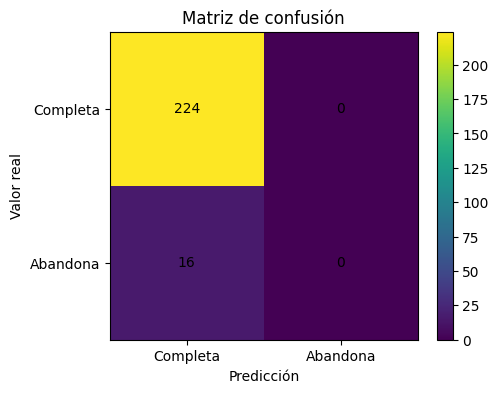

              precision    recall  f1-score   support

    Completa       0.93      1.00      0.97       224
    Abandona       0.00      0.00      0.00        16

    accuracy                           0.93       240
   macro avg       0.47      0.50      0.48       240
weighted avg       0.87      0.93      0.90       240



In [ ]:
# Matriz de confusión
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0, 1], ["Completa", "Abandona"])
plt.yticks([0, 1], ["Completa", "Abandona"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, value, ha="center", va="center")
plt.colorbar()
plt.show()

print(classification_report(y_test, pred, target_names=["Completa", "Abandona"], zero_division=0))

### 7.1 Interpretar errores antes de sacar conclusiones

Una métrica resume; no reemplaza el análisis de errores. Conviene preguntar:
- ¿En qué casos falla?
- ¿Los errores se concentran en algún grupo?
- ¿Qué consecuencias tendría cada error en el contexto real?
- ¿El umbral 0.5 tiene sentido o debería ajustarse según costos y capacidad?
- ¿La información usada estaría disponible al momento de intervenir?

**Precaución:** este dataset fue generado artificialmente con una regla conocida. Los resultados no son evidencia real sobre abandono educativo ni justifican intervenir sobre estudiantes.

## 8. Del resultado a una recomendación

Un proyecto no termina con `model.fit()` ni con una métrica.

Una conclusión responsable suele conectar:

**Hallazgo → evidencia → interpretación → recomendación → limitación**

Ejemplo de estructura (completar con resultados reales):
- **Hallazgo:** observamos ______.
- **Evidencia:** se ve en ______ (tabla/gráfico/métrica).
- **Interpretación:** esto podría indicar ______, aunque no demuestra ______.
- **Recomendación:** proponemos ______.
- **Limitación:** no podemos afirmar ______ porque ______.
- **Próximo paso:** validar ______ con ______.

No presentar asociaciones como causas, ni probabilidades como certezas.

## 9. ¿Y después? Uso, monitoreo y mantenimiento

Si el resultado se usa para tomar decisiones, hay que pensar también en:
- quién recibe la información y con qué frecuencia;
- cómo se integra al proceso de trabajo;
- qué acción habilita y quién es responsable;
- privacidad, seguridad, explicabilidad y posibles daños;
- calidad de datos nuevos y cambios en el contexto (*data drift*);
- monitoreo de desempeño y revisión de errores;
- cuándo actualizar, retirar o reemplazar la solución.

**Desplegar un modelo no es obligatorio en todos los proyectos.** Puede que el entregable sea un informe, un tablero, un análisis exploratorio o una recomendación validada.

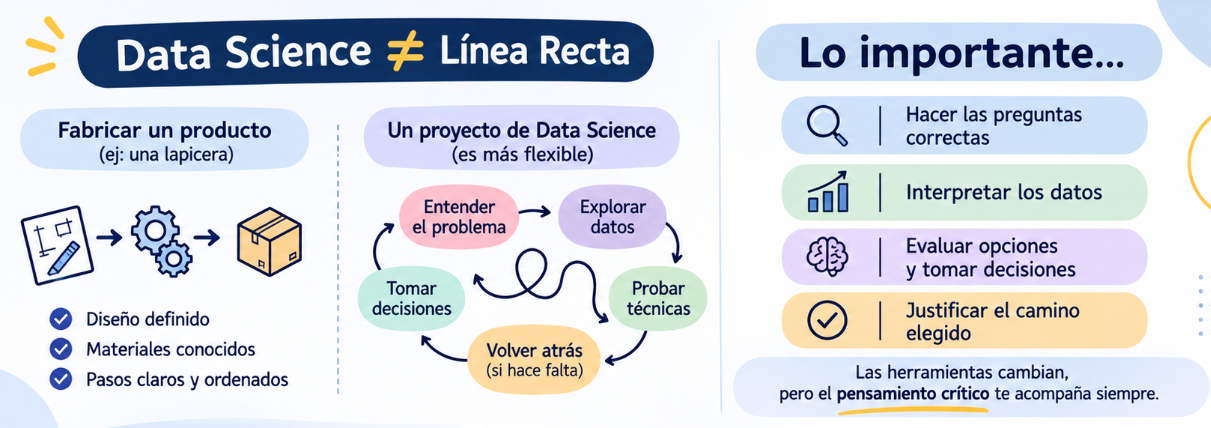


## 10. Checklist final: una guía orientativa para revisar el proyecto

### Problema y contexto
- [ ] ¿Está claro qué problema queremos resolver y para quién?
- [ ] ¿Definimos una decisión concreta y criterios de éxito?
- [ ] ¿Acordamos unidad de análisis, alcance y restricciones?
- [ ] ¿Consideramos una alternativa sin ML?

### Datos y EDA
- [ ] ¿Conocemos origen, permisos y significado de los datos?
- [ ] ¿Documentamos filas, columnas, tipos y target?
- [ ] ¿Revisamos faltantes, duplicados, inconsistencias y valores extremos?
- [ ] ¿Exploramos distribuciones y relaciones relevantes?
- [ ] ¿Documentamos hallazgos, hipótesis y preguntas pendientes?

### Preparación y evaluación
- [ ] ¿La división de datos representa el escenario real?
- [ ] ¿Evitamos fuga de información?
- [ ] ¿Las transformaciones se ajustan solo con train?
- [ ] ¿Tenemos baseline y métricas alineadas con el problema?
- [ ] ¿Analizamos errores, no solo un score?

### Resultados y comunicación
- [ ] ¿Las conclusiones responden a la pregunta inicial?
- [ ] ¿Distinguimos asociación, predicción y causalidad?
- [ ] ¿Explicitamos limitaciones e incertidumbre?
- [ ] ¿Las recomendaciones son accionables y responsables?
- [ ] ¿La comunicación permite entender qué decisión se propone?

### Uso responsable
- [ ] ¿Sabemos quién usará el resultado y cómo?
- [ ] ¿Consideramos privacidad, sesgos e impacto?
- [ ] ¿Definimos validación, monitoreo y mantenimiento si corresponde?

**Este checklist no es una auditoría universal ni una receta obligatoria. Es una ayuda para no olvidar preguntas importantes.**

## 11. Cierre: el proyecto como ciclo

```text
PROBLEMA Y CONTEXTO
        ↓
DATOS → EDA → PREPARACIÓN
  ↑         ↓          ↓
  └── nuevas preguntas / decisiones
                    ↓
       BASELINE → MODELOS (si aplica)
                    ↓
          EVALUACIÓN + ERRORES
                    ↓
      HALLAZGOS → RECOMENDACIONES
                    ↓
       COMUNICACIÓN / USO / IMPACTO
                    ↓
        MONITOREO Y NUEVAS ITERACIONES
```

### Para llevarse
- La metodología ordena el trabajo, pero no elimina el criterio profesional.
- El EDA tiene propósito: entender, cuestionar y decidir qué sigue.
- ML es una herramienta, no el objetivo del proyecto.
- Una buena conclusión debe ser útil, honesta y contextualizada.
- **El valor no está solo en construir modelos: está en transformar datos en decisiones.**